# 01 · The classical wave model in 3D

**Goal:** build the physics the paper uses (sound moving through a head) on a 3D grid, and prove our solver is right
before any quantum computing happens.

* The head is a grid of cubes. Each cube has a sound speed: water 1500, scalp 1600, **skull 2800**, brain 1546,
  **blood 1578 m/s** (a bleed is ~2% faster than brain, as in Guasch et al. 2020).
* A transducer on the scalp gives a 'kick'; we track how much wave energy reaches other cubes over time.
* Two independent classical solvers (step-by-step finite differences, and an exact matrix method) must agree.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # so `import qwave` works from notebooks/
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RESULTS = pathlib.Path.cwd().parent / "results"; RESULTS.mkdir(exist_ok=True)
from qwave import Grid, head_phantom
from qwave.classical import fd_receiver_energy, exact_receiver_energy, total_energy_fd

## The 3D head phantom
A finer 41×41×41 phantom for pictures, and the 7×7×7 version we actually compute with (quantum-sized).

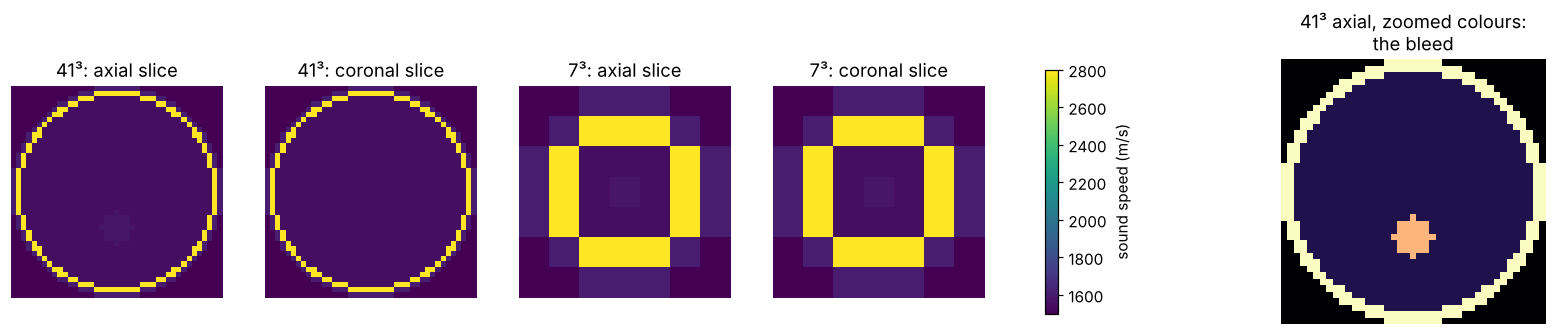

7³ cells per tissue [water, scalp, skull, brain, blood]: [164  98  62  18   1]


In [2]:
big_c, big_lab = head_phantom((41, 41, 41), bleed=(20, 27, 20), bleed_radius=3, normalise=False)
small_c, small_lab = head_phantom((7, 7, 7), bleed=(3, 3, 3), normalise=False)
fig, ax = plt.subplots(1, 5, figsize=(18, 3.6))
for i, (arr, title) in enumerate([(big_c[20], "41³: axial slice"), (big_c[:, 20], "41³: coronal slice"),
                                  (small_c[3], "7³: axial slice"), (small_c[:, 3], "7³: coronal slice")]):
    im = ax[i].imshow(arr, cmap="viridis", vmin=1500, vmax=2800); ax[i].set_title(title); ax[i].axis("off")
fig.colorbar(im, ax=ax[:4], label="sound speed (m/s)", shrink=0.8)
im2 = ax[4].imshow(big_c[20], cmap="magma", vmin=1540, vmax=1585); ax[4].set_title("41³ axial, zoomed colours:\nthe bleed"); ax[4].axis("off")
plt.savefig(RESULTS / "01_phantom.png", bbox_inches="tight"); plt.show()
print("7³ cells per tissue [water, scalp, skull, brain, blood]:", np.bincount(small_lab.ravel(), minlength=5))

## Check 1: energy is conserved (no absorption in this model)

In [3]:
g = Grid((7, 7, 7)); c, lab = head_phantom((7, 7, 7)); c = c.ravel()
for T in (1, 3, 6):
    print(f"t = {T}: total energy = {total_energy_fd(g, c, T, source=g.index(0, 3, 3)):.6f}  (started at 1)")

t = 1: total energy = 1.000002  (started at 1)
t = 3: total energy = 1.000004  (started at 1)
t = 6: total energy = 1.000003  (started at 1)


## Check 2: two independent solvers agree in 3D

max |exact - finite difference| = 7.006751332372559e-08


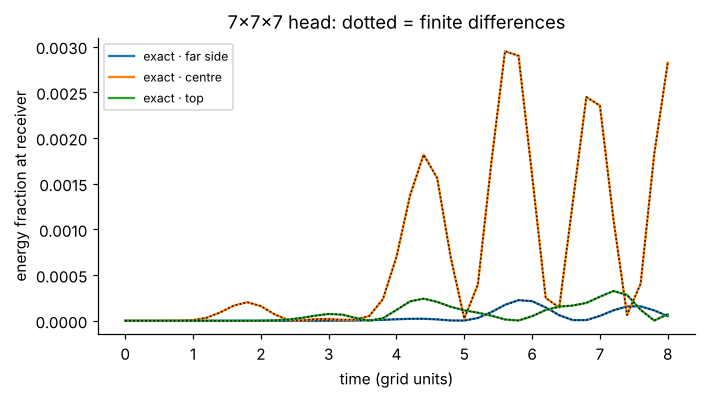

In [4]:
src = g.index(0, 3, 3)                         # transducer on the left side of the head
rx = [g.index(6, 3, 3), g.index(3, 3, 3), g.index(3, 6, 3)]   # far side, centre, top
ts = np.linspace(0, 8, 41)
ex = exact_receiver_energy(g, c, ts, src, rx)
fd = fd_receiver_energy(g, c, ts, src, rx)
print("max |exact - finite difference| =", np.abs(ex - fd).max())
fig, ax = plt.subplots(figsize=(7, 3.5))
for j, name in enumerate(["far side", "centre", "top"]):
    ax.plot(ts, ex[:, j], label=f"exact · {name}"); ax.plot(ts, fd[:, j], "k:", lw=1)
ax.set(xlabel="time (grid units)", ylabel="energy fraction at receiver", title="7×7×7 head: dotted = finite differences")
ax.legend(fontsize=8); plt.savefig(RESULTS / "01_traces.png", bbox_inches="tight"); plt.show()

## How much does a bleed change what the transducers feel?

In [5]:
cb, _ = head_phantom((7, 7, 7), bleed=(3, 3, 3)); cb = cb.ravel()
exb = exact_receiver_energy(g, cb, ts, src, rx)
print("largest change in any receiver signal:", np.abs(exb - ex).max())
print("relative to the signal itself:        ", np.abs(exb - ex).max() / ex.max())

largest change in any receiver signal: 0.00031437208214827976
relative to the signal itself:         0.10661213860917501


**Takeaway:** the classical model conserves energy and two solvers agree to ~1e-6 in 3D. A one-cell bleed changes the
signals by at most ~3×10⁻⁴ in absolute terms (≈10% of that receiver's small signal), so any method (classical or quantum) has to resolve small differences.
That is the number the quantum read-out will have to beat later.